# 2 · Malmquist productivity index: catching up vs frontier shift
The Malmquist index splits **total-factor-productivity change** between two years into
* **EC (efficiency change):** moving closer to, or further from, the frontier (catch-up);
* **TC (technical change):** the frontier itself moving (innovation by best-practice economies).

M > 1 means productivity growth. Indices are computed for every consecutive pair of years (2000-2019) against the world frontier, then chained.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
pwt = pd.read_csv("../data/pwt1001_subset.csv.gz")
oic = pd.read_csv("../data/oic_members.csv")
pwt = pwt[(pwt.year >= 2000)].dropna(subset=["rgdpna", "rnna", "emp", "hc"])
pwt = pwt[(pwt.emp > 0.1)]                                   # drop micro-states (< 100k workers)
pwt["labour_hc"] = pwt.emp * pwt.hc                          # human-capital-adjusted labour
pwt["oic"] = pwt.countrycode.isin(oic.iso3)
print(f"{pwt.countrycode.nunique()} countries ({pwt[pwt.oic].countrycode.nunique()} OIC members), {pwt.year.min()}-{pwt.year.max()}")
from effpanel import malmquist

144 countries (41 OIC members), 2000-2019


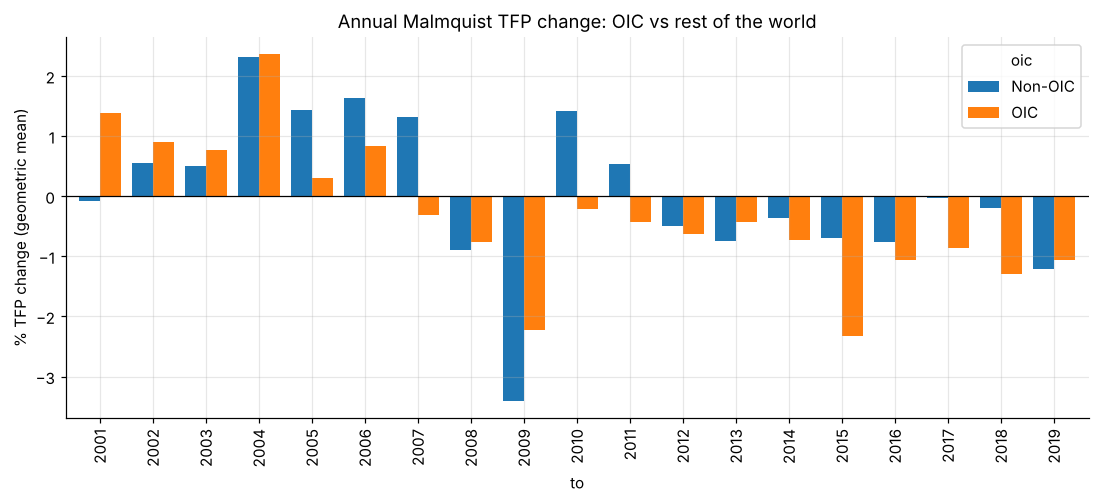

In [2]:
panel = pwt.rename(columns={"countrycode": "entity"})
m = malmquist.malmquist(panel, ["rnna", "labour_hc"], ["rgdpna"])
m = m.merge(pwt.drop_duplicates("countrycode")[["countrycode", "country", "oic"]], left_on="entity", right_on="countrycode")
geo = lambda s: np.exp(np.log(s).mean()) - 1
by_year = m.groupby(["to", "oic"])[["EC", "TC", "Malmquist"]].agg(geo).unstack()
ax = (by_year["Malmquist"] * 100).rename(columns={False: "Non-OIC", True: "OIC"}).plot.bar(figsize=(12, 4.5), width=0.8)
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("% TFP change (geometric mean)")
ax.set_title("Annual Malmquist TFP change: OIC vs rest of the world")
plt.savefig(IMG / "malmquist_by_year.png", bbox_inches="tight"); plt.show()

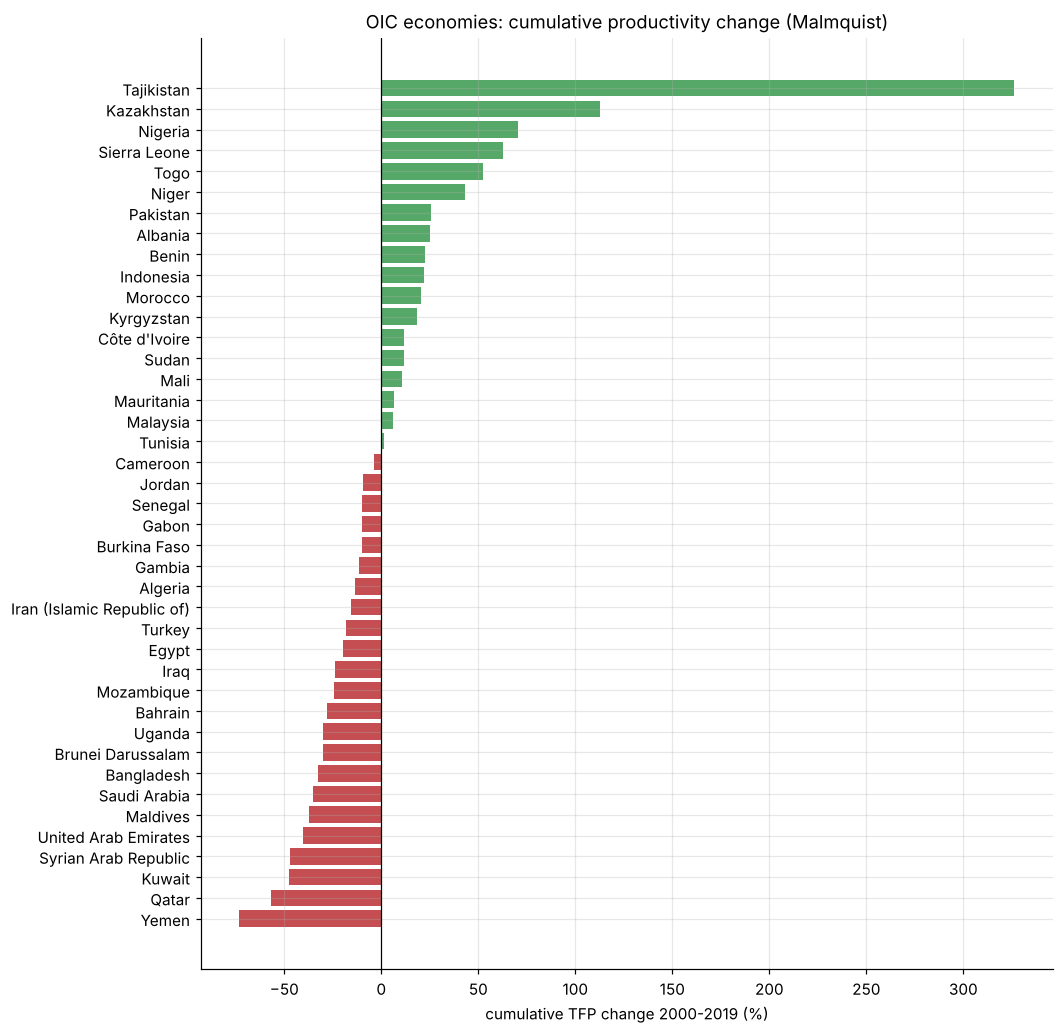

In [3]:
cum = malmquist.cumulative(m).join(m.drop_duplicates("entity").set_index("entity")[["country", "oic"]])
cum = cum[cum.oic].sort_values("Malmquist")
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(cum.country, (cum.Malmquist - 1) * 100, color=np.where(cum.Malmquist > 1, "#55A868", "#C44E52"))
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("cumulative TFP change 2000-2019 (%)")
ax.set_title("OIC economies: cumulative productivity change (Malmquist)")
plt.savefig(IMG / "malmquist_cumulative_oic.png", bbox_inches="tight"); plt.show()

In [4]:
dec = m.groupby("oic")[["EC", "TC", "Malmquist"]].agg(geo) * 100
dec.index = ["Non-OIC", "OIC"]; dec.columns = ["efficiency change (catch-up) %/yr", "technical change (frontier) %/yr", "TFP change %/yr"]
dec.round(2)

,efficiency change (catch-up) %/yr,technical change (frontier) %/yr,TFP change %/yr
Non-OIC,2.00,-1.92,0.03
OIC,1.43,-1.72,-0.32


**What the numbers say (2000-2019).** The world frontier shows **technical regress** (TC < 1, about −1.7 to −1.9% a year): frontier output grew more slowly than capital and effective labour. That is consistent with rapid capital deepening and the post-2008 global productivity slowdown. Most economies offset it by **catching up** (EC > 1). OIC members caught up too (about +1.4% a year) but more slowly than the rest of the world (about +2.0%), so their average TFP change is slightly negative (about −0.3% a year) against roughly zero elsewhere.

**Reading the decomposition.** When TC dominates, productivity gains come from the frontier moving out, mostly driven by the most advanced economies. When EC dominates, countries are *catching up* through better use of existing inputs. A negative EC with a positive TC means a country is falling behind a frontier that keeps advancing.